# **5. YOLO**


---





- 상황
    -  "계량기·표지판의 숫자를 자동으로 찾아 읽고 싶다. 라벨 붙은 사진은 50장뿐이다."
- 목표
    - ① YOLO 데이터 형식 이해
    - ② 사전학습 모델 → **전이학습(파인튜닝)**
    - ③ 백본 동결(freeze) 비교
    - ④ 결과 지표 해석
    - ⑤ **ONNX** 내보내기·추론
    - ⑥ (PC) 웹캠 실시간 탐지 |
- 데이터
    - Roboflow Universe *Numbers v3* (hjk-mrj67/numbers-doqnw, MIT)
    — 숫자 0~9, 10클래스, 학습 35 / 검증 10 / 테스트 5장
- YOLO 모델
    - Ultralytics **YOLO26n** (2026.1 공개, NMS-free) — 비교용 YOLO11n
- 실행 환경
    - Colab 또는 PC. CPU 기본 설정(imgsz=320, 80에폭) 약 6분**, GPU면 `imgsz=640, epochs=100` 권장
    

> ⚠ Ultralytics 라이브러리와 YOLO 모델은 **AGPL-3.0** 라이선스입니다. 상용 서비스에 쓰려면 소스 공개 의무 또는 Enterprise 라이선스를 확인하세요.





---


**(코랩에서)한글 폰트 지정하는 방법**

In [1]:
# 코랩에서 실행
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import shutil
import warnings
import logging

# ── 1. 나눔 폰트 설치 ──────────────────────────────────────────
!apt-get install -y fonts-nanum > /dev/null 2>&1

# ── 2. matplotlib 캐시 디렉터리 삭제 ──────────────────────────
shutil.rmtree(mpl.get_cachedir(), ignore_errors=True)

# ── 3. 폰트 등록 및 유니코드 마이너스 경고 방지 ──────────────────
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (6, 4)

# 수학 기호(마이너스 등)를 일반 텍스트로 처리하도록 설정하여 폰트 에러 차단
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.default'] = 'regular'

# mathtext 및 font_manager 관련 폰트 결함 경고 완전히 무시 설정
logging.getLogger('matplotlib.mathtext').setLevel(logging.ERROR)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib.font_manager')



---



## 0. 설치·환경 설정

In [4]:
# [Colab 명령]
!pip -q install ultralytics

In [3]:

# [Colab 명령] 한글 폰트: !apt-get -qq install -y fonts-nanum > /dev/null ; 이후 세션 다시 시작
import os, glob, zipfile, time, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import torch
import ultralytics
from ultralytics import YOLO
from PIL import Image

def set_korean_font():
    installed = {f.name for f in fm.fontManager.ttflist}
    for name in ["Malgun Gothic", "NanumGothic", "AppleGothic", "Noto Sans CJK KR"]:
        if name in installed:
            plt.rcParams["font.family"] = name; break
    plt.rcParams["axes.unicode_minus"] = False
set_korean_font()

GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"
IMGSZ = 640 if GPU else 320          # CPU에서는 해상도를 낮춰 시간 절약
EPOCHS = 100 if GPU else 80
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| GPU:", GPU)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.191 | torch 2.11.0+cu130 | GPU: True




---



## **5-0. YOLO 탐지기 비교**
- **YOLO(You Only Look Once, 2016**)는 이미지 전체를 한 번의 신경망 처리로 분석하여 객체의 종류와 위치(Bounding Box)를 동시에 예측하는 실시간 객체 탐지 모델입니다.


### **[실습] YOLO11n(NMS 사용) vs YOLO26n(NMS-free) vs RT-DETR-l(트랜스포머) 비교**

같은 사진(ultralytics 패키지에 들어 있는 bus.jpg)으로 CPU 추론 시간과 결과를 비교합니다.

In [ ]:
# !pip install ultralytics

#### **1. YOLO11n(NMS 사용) vs YOLO26n(NMS-free) vs RT-DETR-l(트랜스포머) 비교**


모델             파라미터(M)    CPU 추론(ms)    상자 수  클래스
YOLO11n            2.6            24       5  bus, person
YOLO26n            2.6            18       5  bus, person
RT-DETR-l         33.0            86       9  bus, fire hydrant, person, tie, traffic light


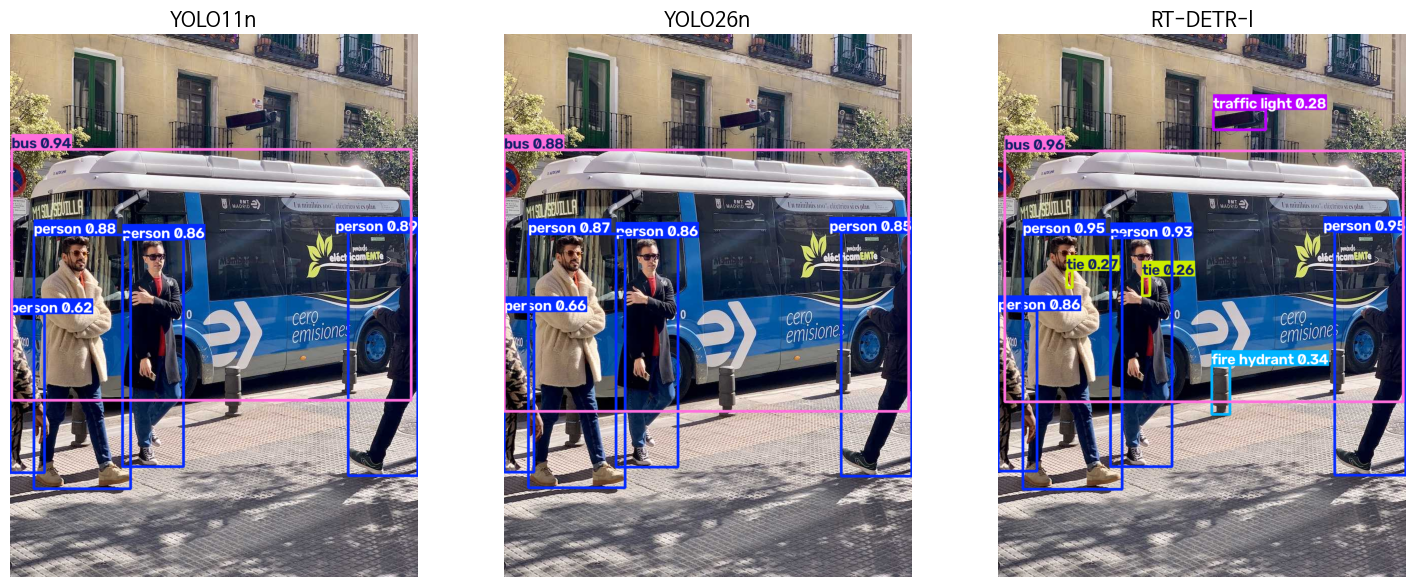

In [5]:
from ultralytics import YOLO, RTDETR
from ultralytics.utils import ASSETS          # 패키지 내장 예제 이미지 폴더
import time
import matplotlib.pyplot as plt
import torch
from torchvision import ops

img_path = str(ASSETS / "bus.jpg")

detectors = {"YOLO11n": YOLO("yolo11n.pt"),
             "YOLO26n": YOLO("yolo26n.pt"),
             "RT-DETR-l": RTDETR("rtdetr-l.pt")}
rows, plots = [], []
for name, m in detectors.items():
    m.predict(img_path, verbose=False)                          # 첫 실행(워밍업) 제외
    t0 = time.time()
    for _ in range(3):
        r = m.predict(img_path, conf=0.25, verbose=False)[0]
    ms = (time.time() - t0) / 3 * 1000
    n_param = sum(p.numel() for p in m.model.parameters()) / 1e6
    names = [r.names[int(c)] for c in r.boxes.cls]
    rows.append((name, n_param, ms, len(r.boxes), ", ".join(sorted(set(names)))))
    plots.append((name, r.plot()[:, :, ::-1]))                  # BGR → RGB

print()
print(f"{'모델':<10}{'파라미터(M)':>12}{'CPU 추론(ms)':>14}{'상자 수':>8}  클래스")
for n, p, ms, k, cls in rows:
    print(f"{n:<10}{p:>12.1f}{ms:>14.0f}{k:>8}  {cls}")

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, (n, im) in zip(axes, plots):
    ax.imshow(im); ax.set_title(n); ax.axis("off")
plt.tight_layout(); plt.show()

#### **2. 임계값(conf · iou) 조정하기**
임계값(conf · iou)이 결과를 바꾼다 — YOLO11n

In [7]:
m = detectors["YOLO11n"]
print(f"{'conf':>6}{'iou(NMS)':>10}{'상자 수':>8}")
for conf, iou_thr in [(0.5, 0.7), (0.25, 0.7), (0.05, 0.7), (0.05, 0.95)]:
    r = m.predict(img_path, conf=conf, iou=iou_thr, verbose=False)[0]
    print(f"{conf:>6}{iou_thr:>10}{len(r.boxes):>8}")

  conf  iou(NMS)    상자 수
   0.5       0.7       5
  0.25       0.7       5
  0.05       0.7      11
  0.05      0.95      20
   0.7       0.7       4
   0.5       0.3       5
   0.7       0.3       4
   0.3       0.3       5


**관찰** : conf를 낮추면 상자가 늘고(Recall↑, Precision↓), NMS의 iou를 0.95로 올리면 겹친 중복 상자가 거의 지워지지 않습니다.

### **[선택] 2-stage 탐지기** — torchvision Faster R-CNN

`RUN_FRCNN = True` 로 바꾸면 Faster R-CNN(Ren et al., 2015)으로 같은 사진을 탐지합니다. 가중치 약 160MB, **GPU 권장**.
- [주의!] GPU에서 실행하기

In [9]:
RUN_FRCNN = True
if RUN_FRCNN:
    from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
    from torchvision.io import read_image
    w = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
    frcnn = fasterrcnn_resnet50_fpn_v2(weights=w).eval()
    x = w.transforms()(read_image(img_path))
    t0 = time.time()
    with torch.no_grad():
        out = frcnn([x])[0]
    keep = out["scores"] > 0.5
    print('모델     상자 수   추론(ms)    탐지 클래스')
    print(f"\nFaster R-CNN: {keep.sum().item()}개, {1000 * (time.time() - t0):.0f} ms",
          [w.meta["categories"][i] for i in out["labels"][keep]])

모델     상자 수   추론(ms)    클래스

Faster R-CNN: 6개, 7675 ms ['person', 'bus', 'person', 'person', 'person', 'tie']




---



# **------------------------------------------------**

# **[YOLO 실습]: 데이터로 학습부터 배포까지**


### **[실습] YOLO로 손글씨 숫자 데이터 탐지하기**
- 준비된 배포 파일과 YOLO 모델을 이용하여 숫자 탐지가 제대로 되는지 확인해 보세요.
- 만약 탐지가 제대로 안된다면 데이터를 학습시켜 탐지 모델을 만들어: https://universe.roboflow.com/hjk-mrj67/numbers-doqnw

## **5-1. 데이터 준비** — 압축 풀기와 `data.yaml`

Roboflow에서 "YOLOv8" 형식으로 내려받은 압축 파일을 그대로 씁니다.

```
datasets/numbers/
├── data.yaml          ← 클래스 이름·경로
├── train/images/*.jpg   train/labels/*.txt
├── valid/images/*.jpg   valid/labels/*.txt
└── test/images/*.jpg    test/labels/*.txt
```

In [11]:
ZIP = "Numbers.v3-numbers-50.yolov8.zip"     # 강의 자료실에서 받아 노트북과 같은 폴더에 두세요
DATA_DIR = os.path.abspath("datasets/numbers")
if not os.path.exists(os.path.join(DATA_DIR, "train")):
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(DATA_DIR)

# Roboflow의 상대경로(../train/images)는 환경마다 깨지기 쉬움 → 절대경로로 다시 씁니다.
names = [str(i) for i in range(10)]
yaml_text = (f"path: {DATA_DIR}\ntrain: train/images\nval: valid/images\ntest: test/images\n"
             f"nc: {len(names)}\nnames: {names}\n")
DATA_YAML = os.path.join(DATA_DIR, "data_local.yaml")
with open(DATA_YAML, "w", encoding="utf-8") as f:
    f.write(yaml_text)
print(yaml_text)
for s in ["train", "valid", "test"]:
    print(f"{s:<6} 이미지 {len(glob.glob(f'{DATA_DIR}/{s}/images/*')):>3}장")

path: /content/datasets/numbers
train: train/images
val: valid/images
test: test/images
nc: 10
names: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

train  이미지  35장
valid  이미지  10장
test   이미지   5장


### **1. 학습용 이미지 데이터와 정답 라벨** = `클래스 cx cy w h` (0~1로 정규화)

000054_jpg.rf.d8c5dcc3f506739aae3a5ef590634eb0.txt 
3 0.2484375 0.48828125 0.046875 0.05390625
6 0.315625 0.709375 0.05390625 0.05703125
8 0.49375 0.6890625 0.18203125 0.2265625
6 0.8046875 0.79609375 0.04375 0.05703125


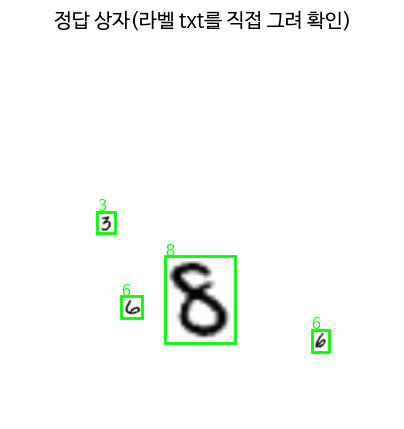

In [12]:
img_file = sorted(glob.glob(f"{DATA_DIR}/train/images/*"))[0]                    # 학습용 이미지
lab_file = img_file.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"   # 정답 라벨
lines = open(lab_file).read().strip().splitlines()
print(os.path.basename(lab_file), "\n" + "\n".join(lines[:5]))

im = Image.open(img_file); W, H = im.size
fig, ax = plt.subplots(figsize=(5, 5)); ax.imshow(im)
for ln in lines:
    c, cx, cy, w, h = map(float, ln.split())
    x1, y1 = (cx - w / 2) * W, (cy - h / 2) * H
    ax.add_patch(plt.Rectangle((x1, y1), w * W, h * H, fill=False, ec="lime", lw=2))
    ax.text(x1, y1 - 3, names[int(c)], color="lime", fontsize=11, weight="bold")
ax.set_title("정답 상자(라벨 txt를 직접 그려 확인)")
ax.axis("off")
plt.show()

### **2. 클래스별 객체 분포 확인** — 실무에서 가장 먼저 볼 것

        0   1   2   3   4   5   6   7   8   9
train  20  17  16  26  26  13  26  13  21  21
valid   2   6   8   6   9   1   8   7   3   3
test    6   3   4   6   2   5   6   6   2   4


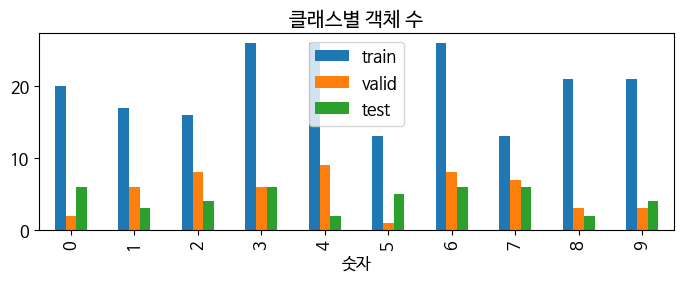

In [14]:
counts = {s: np.zeros(10, int) for s in ["train", "valid", "test"]}
for s in counts:
    for t in glob.glob(f"{DATA_DIR}/{s}/labels/*.txt"):
        for ln in open(t).read().split("\n"):
            if ln.strip():
                counts[s][int(ln.split()[0])] += 1
df_cnt = pd.DataFrame(counts, index=names)
print(df_cnt.T)
df_cnt.plot.bar(figsize=(7, 3), title="클래스별 객체 수"); plt.xlabel("숫자"); plt.tight_layout(); plt.show()

## **5-2. 사전학습(COCO 80클래스) 모델을 그대로 쓰면**?

COCO에는 우리가 이번에 탐지할 '숫자' 클래스가 없습니다 → **우리 문제에 맞게 다시 학습(전이학습)** 해야 합니다.

In [15]:
TEST_IMG = "number.jpg"            # 강의 자료실 파일 (없으면 테스트셋 첫 장 사용)
if not os.path.exists(TEST_IMG):
    TEST_IMG = sorted(glob.glob(f"{DATA_DIR}/test/images/*"))[0]
coco = YOLO("yolo26n.pt")
r = coco.predict(TEST_IMG, conf=0.25, verbose=False)[0]
print("COCO 사전학습 YOLO26n이 찾은 것:", [r.names[int(c)] for c in r.boxes.cls] or "없음")

COCO 사전학습 YOLO26n이 찾은 것: ['kite', 'kite', 'kite', 'kite', 'kite', 'kite', 'kite', 'kite', 'kite']


## **5-3. 전이학습 — YOLO26n 파인튜닝**

| 주요 인자 | 값 | 의미 |
|---|---|---|
| `data` | data_local.yaml | 데이터 정의 |
| `epochs` | 80 (CPU) / 100 (GPU) | 전체 데이터를 몇 번 볼지 |
| `imgsz` | 320 (CPU) / 640 (GPU) | 입력 해상도 |
| `batch` | 8 | 한 번에 처리할 이미지 수 |
| `fliplr` | **0.0** | ⚠ 숫자는 좌우 반전하면 다른 글자가 됨 → 증강도 도메인에 맞게 |
| `freeze` | None / 10 | 앞쪽 10개 층(백본) 동결 여부 |
| `seed`, `deterministic` | 42, True | 재현성 |

In [16]:
'''
IMGSZ = 640 if GPU else 320          # CPU에서는 해상도를 낮춰 시간 절약
EPOCHS = 100 if GPU else 80
'''
PROJECT = os.path.abspath("runs/numbers")   # 절대경로로 지정해야 저장 위치가 헷갈리지 않음
COMMON = dict(data=DATA_YAML,
              epochs=EPOCHS,
              imgsz=IMGSZ,
              batch=8, device=DEVICE, workers=0,
              fliplr=0.0, seed=42, deterministic=True, plots=True, verbose=False, project=PROJECT)

def train(weights, name, **kw):
    t0 = time.time()
    model = YOLO(weights)
    model.train(name=name, exist_ok=True, **COMMON, **kw)
    sec = time.time() - t0
    run_dir = str(model.trainer.save_dir)                 # 실제 저장 폴더
    best = YOLO(os.path.join(run_dir, "weights", "best.pt"))
    m = best.val(data=DATA_YAML, imgsz=IMGSZ, device=DEVICE, split="val", verbose=False, plots=False)
    return dict(name=name, sec=sec, mAP50=m.box.map50, mAP50_95=m.box.map, P=m.box.mp, R=m.box.mr, model=best, dir=run_dir)

res_ft = train("yolo26n.pt", "yolo26n_ft")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_ft.items() if k not in ("model", "dir")})

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/numbers/data_local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_ft, nbs=64, nms=None, opset=None, optimi



---



## **-----------------------------------**

## **[실습] 비교 실험**
다음 방법으로 모델 학습 후 성능을 비교해 보세요
- 백본 동결 · 처음부터 학습 · 이전 세대(YOLO11n) 방식을 비교해 보세요.

## **5-4. 비교 실험** — 백본 동결 · 처음부터 학습 · 이전 세대(YOLO11n)

`RUN_COMPARE = True` 이면 세 가지를 같은 조건으로 더 학습합니다 (CPU 약 20분, 수업 중에는 교수 결과로 대신).

In [17]:
RUN_COMPARE = True   # True: 3가지 비교 학습 추가 (CPU 약 20분)
results = [res_ft]
if RUN_COMPARE:
    results.append(train("yolo26n.pt", "yolo26n_freeze10", freeze=10))   # 백본 동결
    results.append(train("yolo26n.yaml", "yolo26n_scratch"))              # 사전학습 없이
    results.append(train("yolo11n.pt", "yolo11n_ft"))                     # 이전 세대
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("model", "dir")} for r in results]).round(3)
print(df.to_string(index=False))

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/numbers/data_local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_freeze10, nbs=64, nms=None, opset=None, op

## **5-5. 학습 결과 읽기** — `results.csv` · 혼동행렬

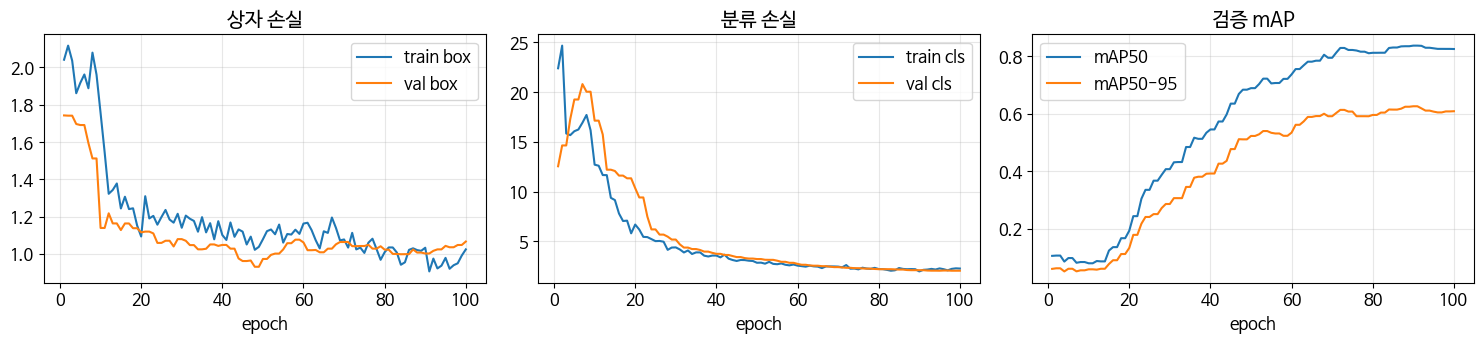

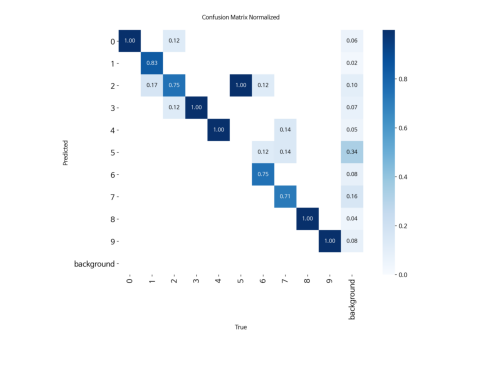

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,922 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 599.7±107.7 MB/s, size: 10.4 KB)
val: Scanning /content/datasets/numbers/valid/labels.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 2.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 7.1it/s 0.1s
                   all         10         53      0.955      0.675      0.837      0.626
Speed: 0.4ms preprocess, 6.7ms inference, 0.0ms loss, 1.5ms postprocess per image
클래스별 mAP50-95: {'0': 0.85, '1': 0.44, '2': 0.66, '3': 0.76, '4': 0.69, '5': 0.1, '6': 0.63, '7': 0.73, '8': 0.66, '9': 0.75}


In [18]:
run_dir = res_ft["dir"]
log = pd.read_csv(f"{run_dir}/results.csv"); log.columns = [c.strip() for c in log.columns]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(log["epoch"], log["train/box_loss"], label="train box"); axes[0].plot(log["epoch"], log["val/box_loss"], label="val box")
axes[0].set_title("상자 손실"); axes[0].legend()
axes[1].plot(log["epoch"], log["train/cls_loss"], label="train cls"); axes[1].plot(log["epoch"], log["val/cls_loss"], label="val cls")
axes[1].set_title("분류 손실"); axes[1].legend()
axes[2].plot(log["epoch"], log["metrics/mAP50(B)"], label="mAP50"); axes[2].plot(log["epoch"], log["metrics/mAP50-95(B)"], label="mAP50-95")
axes[2].set_title("검증 mAP"); axes[2].legend()
for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

cm_png = f"{run_dir}/confusion_matrix_normalized.png"
if os.path.exists(cm_png):
    plt.figure(figsize=(6, 5)); plt.imshow(Image.open(cm_png)); plt.axis("off"); plt.show()

# 클래스별 AP (검증셋)
best = res_ft["model"]
mv = best.val(data=DATA_YAML, imgsz=IMGSZ, device=DEVICE, verbose=False, plots=False)
print("클래스별 mAP50-95:", {names[i]: round(float(a), 2) for i, a in zip(mv.box.ap_class_index, mv.box.maps[mv.box.ap_class_index])})

## **5-6. 추론** — 학습한 모델로 숫자 찾기
(+ 교수가 250에폭 학습한 YOLOv8n과 비교)

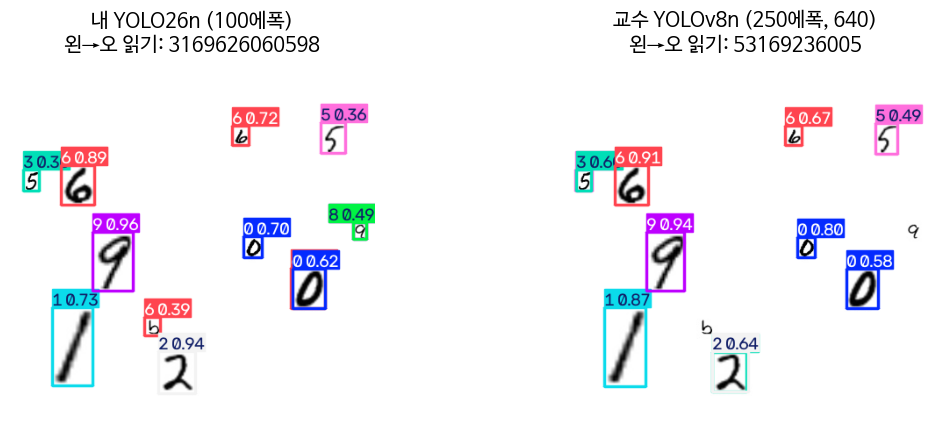

In [22]:
cands = [(f"내 YOLO26n ({EPOCHS}에폭)", best)]
if os.path.exists("numbers/best.pt"):
    cands.append(("교수 YOLOv8n (250에폭, 640)", YOLO("numbers/best.pt")))
fig, axes = plt.subplots(1, len(cands), figsize=(6 * len(cands), 4.5))
axes = np.atleast_1d(axes)
for ax, (t, m) in zip(axes, cands):
    r = m.predict(TEST_IMG, conf=0.25, imgsz=IMGSZ if "내" in t else 640, verbose=False)[0]
    digits = sorted(zip(r.boxes.xyxy[:, 0].tolist(), [r.names[int(c)] for c in r.boxes.cls]))
    ax.imshow(r.plot()[:, :, ::-1]); ax.axis("off")
    ax.set_title(f"{t}\n왼→오 읽기: {''.join(d for _, d in digits)}")
plt.tight_layout(); plt.show()

## **5-7. 배포** — ONNX로 내보내기 (엣지·서버 공통 표준)

| 형식 | 인자 | 용도 |
|---|---|---|
| ONNX | `format="onnx"` | 범용 (ONNX Runtime, 다양한 언어) |
| TensorRT | `format="engine"` | NVIDIA GPU 최고 속도 |
| OpenVINO | `format="openvino"` | 인텔 CPU |
| TFLite / CoreML | `format="tflite"` / `"coreml"` | 모바일 |

In [23]:
onnx_path = best.export(format="onnx", imgsz=IMGSZ, dynamic=False, verbose=False)
print("내보낸 파일:", onnx_path, f"({os.path.getsize(onnx_path) / 1e6:.1f} MB)")
onnx_model = YOLO(onnx_path, task="detect")

def bench(m, n=10):
    m.predict(TEST_IMG, imgsz=IMGSZ, verbose=False)
    t0 = time.time()
    for _ in range(n):
        r = m.predict(TEST_IMG, imgsz=IMGSZ, verbose=False)[0]
    return (time.time() - t0) / n * 1000, len(r.boxes)

for t, m in [("PyTorch .pt", best), ("ONNX", onnx_model)]:
    ms, k = bench(m)
    print(f"{t:<12} {ms:6.1f} ms/장  상자 {k}개")

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,391,922 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs/numbers/yolo26n_ft/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 14, 8400) (5.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 293ms
Prepared 4 packages in 542ms
Installed 4 packages in 35ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimm

## 5-8. (코랩) 웹캠 실시간 탐지

Colab에서는 웹캠을 `cv2.VideoCapture`로 열 수 없습니다. **본인 PC(VS Code 등)** 에서 `RUN_WEBCAM = True` 로 실행하세요. `q` 키로 종료.

In [ ]:
import cv2
import numpy as np
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import io
from PIL import Image as PILImage

# ── 1. JavaScript로 웹캠 실시간 스트리밍 구성 ──────────────────
# 이 함수는 브라우저의 웹캠 영상을 코랩 Python 커널로 받아옵니다.

def video_stream():
  js = Javascript('''
    var video;
    var stream;
    var delay = 50; // 프레임 주기 (ms)
    var canvas;

    async function init() {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = '웹캠 종료 (Stop)';
      capture.style.display = 'block';
      capture.style.marginBottom = '10px';

      video = document.createElement('video');
      video.style.display = 'block';
      stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(capture);
      div.appendChild(video);

      video.srcObject = stream;
      await video.play();

      canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;

      capture.onclick = function() {
        stream.getVideoTracks()[0].stop();
        div.remove();
      };
    }

    async function captureFrame() {
      if (!stream || stream.getVideoTracks()[0].readyState === 'ended') {
        return null;
      }
      canvas.getContext('2d').drawImage(video, 0, 0);
      return canvas.toDataURL('image/jpeg', 0.8);
    }

    window.initWebcam = init;
    window.captureWebcamFrame = captureFrame;
    ''')
  display(js)

def js_to_image(js_reply):
  image_bytes = b64decode(js_reply.split(',')[1])
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  img = cv2.imdecode(jpg_as_np, flags=1)
  return img

# ── 2. 코랩에서 웹캠 실행 및 YOLO 추론 ──────────────────────────
RUN_WEBCAM = True # 코랩 웹캠 실행 활성화

if RUN_WEBCAM:
    # 웹캠 스트림 초기화
    video_stream()
    eval_js('initWebcam()')

    # 실시간 프레임 출력을 위한 display target
    img_display = display(display_id=True)

    while True:
        # 브라우저로부터 현재 프레임을 가져옴
        js_reply = eval_js('captureWebcamFrame()')
        if js_reply is None:
            print("웹캠이 정지되었습니다.")
            break

        # 이미지를 OpenCV 포맷으로 변환
        frame = js_to_image(js_reply)

        # YOLO 모델로 예측 진행 (best 모델 사용)
        r = best.predict(frame, conf=0.4, imgsz=IMGSZ, verbose=False)[0]

        # 결과를 시각화한 이미지를 그려서 가져옴
        annotated_frame = r.plot()

        # 이미지를 인코딩하여 화면 갱신
        _, keep = cv2.imencode('.jpg', annotated_frame)
        img_display.update(Image(data=keep.tobytes()))

## **5-9. (참고) 하이퍼파라미터 자동 탐색** — `model.tune()`

유전 알고리즘(진화) 방식으로 학습률·증강 값 등을 바꿔 가며 반복 학습합니다. **GPU에서도 수 시간** 걸리므로 수업에서는 실행하지 않습니다.
교수 실측 예: 25회 반복, 약 24시간(87,115초), 최고 fitness 0.747 (mAP50 0.969, mAP50-95 0.722).

In [ ]:
RUN_TUNE = False
if RUN_TUNE:
    YOLO("yolo26n.pt").tune(data=DATA_YAML, epochs=30, iterations=25, imgsz=IMGSZ, optimizer="AdamW",
                            plots=False, save=False, val=True)